In [1]:
!pip install pulse2percept

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.0/10.0 MB 9.0 MB/s  0:00:01


In [2]:
import numpy as np, pandas as pd, itertools, time
import matplotlib.pyplot as plt
from skimage.measure import label, regionprops
from pulse2percept.implants.retina.argus import ArgusII
from pulse2percept.models.retina.beyeler2019 import AxonMapModel

XY, FIELD = 0.25, (-22, 22)
implant = ArgusII()
electrodes = list(implant.electrode_names)

def make_model(rho, lam):
    m = AxonMapModel(implant, rho=rho, lam=lam, step=XY, xrange=FIELD, yrange=FIELD, verbose=False)
    if hasattr(m, "build"):
        m.build()
    return m

def shape_features(img):
    if img.max() <= 0:
        return np.array([0.0, 0.0])
    mask = img > 0.1 * img.max()
    props = max(regionprops(label(mask)), key=lambda p: p.area)
    return np.array([props.area * XY**2,
                     1 - props.minor_axis_length / max(props.major_axis_length, 1e-6)])

def patient_features(rho, lam):
    m = make_model(rho, lam)
    return np.array([shape_features(np.asarray(m.predict_percept({e: 1.0}).data).squeeze())
                     for e in electrodes])     # (60 electrodes, 2 features)

t0 = time.time(); _ = patient_features(200, 500)
print(f"60 electrodes, one patient took {time.time() - t0:.0f}s")

60 electrodes, one patient took 20s


In [3]:
rho_grid = np.linspace(100, 500, 9)      # every 50 µm
lam_grid = np.linspace(200, 1400, 9)     # every 150 µm
TH = np.array(list(itertools.product(rho_grid, lam_grid)))   # (81, 2): candidate (rho, lam)

t0 = time.time()
LIBF = []
for i, (r, l) in enumerate(TH):
    LIBF.append(patient_features(r, l))
    if (i + 1) % 9 == 0:
        print(f"{i + 1}/81 built ({time.time() - t0:.0f}s)")
LIBF = np.array(LIBF)                    # (81, 60, 2)

np.savez("library.npz", TH=TH, LIBF=LIBF)   # save, in case Colab disconnects
from google.colab import files; files.download("library.npz")

9/81 built (94s)
18/81 built (183s)
27/81 built (274s)
36/81 built (366s)
45/81 built (459s)
54/81 built (552s)
63/81 built (648s)
72/81 built (746s)
81/81 built (854s)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [4]:
rng = np.random.default_rng(0)
test_patients = [(rng.uniform(100, 500), rng.uniform(200, 1400)) for _ in range(15)]
test_feats = [patient_features(r, l) for r, l in test_patients]
print("Test patients (rho, lam):", [(round(r), round(l)) for r, l in test_patients])

Test patients (rho, lam): [(355, 524), (116, 220), (425, 1295), (343, 1075), (317, 1322), (426, 203), (443, 240), (392, 411), (445, 850), (220, 707), (111, 349), (368, 977), (346, 660), (499, 1377), (374, 981)]


In [5]:
G = len(TH)
NOISE = 0.10                                         # noise on observed features (as before)
REL = 0.15                                           # model's assumed relative noise (a bit larger,
FLOOR = 0.05 * LIBF.reshape(-1, 2).std(0)            #  to allow for patients between grid points)

def loglik(Y, e):
    """Log-likelihood of observations Y (S, 2) at electrode e for every candidate patient -> (S, G)."""
    mu = LIBF[None, :, e, :]
    sd = REL * np.abs(mu) + FLOOR
    return -0.5 * (((Y[:, None, :] - mu) / sd) ** 2).sum(-1) - np.log(sd).sum(-1)

def normalize(logp):
    logp = logp - logp.max(-1, keepdims=True)
    p = np.exp(logp)
    return p / p.sum(-1, keepdims=True)

def entropy(p):
    return -(p * np.log(p + 1e-300)).sum(-1)

def expected_info_gain(logpost, e, rng, S=30):
    """How much testing electrode e is expected to reduce uncertainty (Monte Carlo estimate)."""
    p = normalize(logpost)
    idx = rng.choice(G, S, p=p)                          # plausible patients under current belief
    Y = LIBF[idx, e, :] * (1 + NOISE * rng.standard_normal((S, 2)))   # what we might observe
    new_post = normalize(logpost[None, :] + loglik(Y, e))
    return entropy(p) - entropy(new_post).mean()

def error(est, truth):
    """Combined error as a fraction of each parameter's range (same as your earlier project)."""
    return abs(est[0] - truth[0]) / 400 + abs(est[1] - truth[1]) / 1200

In [6]:
# Static ranking: electrodes ordered by information gain under the prior (computed once, not adaptive)
srng = np.random.default_rng(123)
prior_eig = np.array([expected_info_gain(np.zeros(G), e, srng, S=300) for e in range(60)])
static_order = list(np.argsort(-prior_eig))
print("Most informative electrodes under the prior:", [electrodes[i] for i in static_order[:8]])

def run(policy, F_true, truth, rng, K=10):
    logpost, used, errs = np.zeros(G), [], []
    for _ in range(K):
        avail = [e for e in range(60) if e not in used]
        if policy == "Random":
            e = int(rng.choice(avail))
        elif policy == "Static ranking":
            e = next(x for x in static_order if x not in used)
        else:  # Adaptive (Bayesian)
            e = max(avail, key=lambda a: expected_info_gain(logpost, a, rng))
        y = F_true[e] * (1 + NOISE * rng.standard_normal(2))      # run the test
        logpost += loglik(y[None], e)[0]                          # Bayes' rule update
        used.append(e)
        errs.append(error(normalize(logpost) @ TH, truth))
    return errs

policies = ["Random", "Static ranking", "Adaptive (Bayesian)"]
REPEATS, K = 4, 10
results = {p: [] for p in policies}
t0 = time.time()
for i, (truth, F) in enumerate(zip(test_patients, test_feats)):
    for r in range(REPEATS):
        for p in policies:
            results[p].append(run(p, F, truth, np.random.default_rng(1000 * i + r), K))
    print(f"patient {i + 1}/15 done ({time.time() - t0:.0f}s)")

for p in policies:
    m = np.mean(results[p], axis=0)
    print(f"{p:20s}: " + "  ".join(f"{v:.3f}" for v in m[[0, 1, 2, 4, 9]]) + "   (after 1, 2, 3, 5, 10 tests)")

Most informative electrodes under the prior: ['E10', 'F10', 'A10', 'F7', 'E8', 'E9', 'F9', 'B10']
patient 1/15 done (2s)
patient 2/15 done (3s)
patient 3/15 done (4s)
patient 4/15 done (6s)
patient 5/15 done (7s)
patient 6/15 done (9s)
patient 7/15 done (11s)
patient 8/15 done (12s)
patient 9/15 done (13s)
patient 10/15 done (14s)
patient 11/15 done (15s)
patient 12/15 done (15s)
patient 13/15 done (16s)
patient 14/15 done (17s)
patient 15/15 done (18s)
Random              : 0.117  0.085  0.065  0.052  0.050   (after 1, 2, 3, 5, 10 tests)
Static ranking      : 0.081  0.060  0.048  0.050  0.053   (after 1, 2, 3, 5, 10 tests)
Adaptive (Bayesian) : 0.098  0.064  0.054  0.052  0.049   (after 1, 2, 3, 5, 10 tests)


In [7]:
def run2(policy, F_true, truth, rng, K=10, S=30, rel=REL):
    global REL
    old = REL; REL = rel
    logpost, used, errs = np.zeros(G), [], []
    for _ in range(K):
        avail = [e for e in range(60) if e not in used]
        if policy == "Static ranking":
            e = next(x for x in static_order if x not in used)
        elif policy == "Adaptive (Bayesian)":
            e = max(avail, key=lambda a: expected_info_gain(logpost, a, rng, S=S))
        else:
            e = int(rng.choice(avail))
        y = F_true[e] * (1 + NOISE * rng.standard_normal(2))
        logpost += loglik(y[None], e)[0]
        used.append(e)
        errs.append(error(normalize(logpost) @ TH, truth))
    REL = old
    return errs

configs = [("Static ranking", 30, 0.15),
           ("Adaptive (Bayesian)", 30, 0.15),
           ("Adaptive (Bayesian)", 200, 0.15),     # Cause 1: more accurate information-gain estimates
           ("Static ranking", 30, 0.25),           # Cause 2: less overconfident model
           ("Adaptive (Bayesian)", 200, 0.25)]     # both fixes
res2 = {}
t0 = time.time()
for name, S, rel in configs:
    key = f"{name}, S={S}, model noise={rel}"
    res2[key] = [run2(name, F, truth, np.random.default_rng(1000 * i + r), K, S, rel)
                 for i, (truth, F) in enumerate(zip(test_patients, test_feats)) for r in range(REPEATS)]
    m = np.mean(res2[key], axis=0)
    print(f"{key:45s}: " + "  ".join(f"{v:.3f}" for v in m[[0, 1, 2, 4, 9]])
          + f"   ({time.time() - t0:.0f}s)")

Static ranking, S=30, model noise=0.15       : 0.081  0.060  0.048  0.050  0.053   (0s)
Adaptive (Bayesian), S=30, model noise=0.15  : 0.098  0.064  0.054  0.052  0.049   (18s)
Adaptive (Bayesian), S=200, model noise=0.15 : 0.094  0.064  0.049  0.053  0.056   (61s)
Static ranking, S=30, model noise=0.25       : 0.106  0.068  0.054  0.051  0.055   (61s)
Adaptive (Bayesian), S=200, model noise=0.25 : 0.119  0.070  0.059  0.056  0.048   (106s)


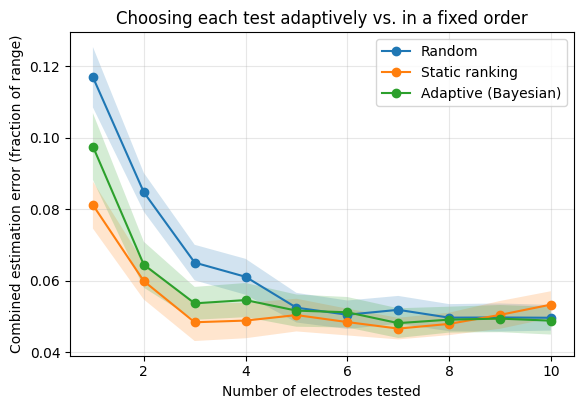

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [8]:
plt.figure(figsize=(6.5, 4.2))
ks = np.arange(1, K + 1)
for p in policies:
    a = np.array(results[p])
    m, se = a.mean(0), a.std(0) / np.sqrt(len(a))
    plt.plot(ks, m, marker="o", label=p)
    plt.fill_between(ks, m - se, m + se, alpha=0.2)
plt.xlabel("Number of electrodes tested"); plt.ylabel("Combined estimation error (fraction of range)")
plt.title("Choosing each test adaptively vs. in a fixed order")
plt.legend(); plt.grid(alpha=0.3)
plt.savefig("adaptive_selection.png", dpi=200, bbox_inches="tight"); plt.show()
files.download("adaptive_selection.png")